# 2. Exploración de los datos

Antes de entrenar conviene conocer bien los datos. Un **análisis exploratorio** (EDA, *exploratory data analysis*) los mira desde varios ángulos para entender qué hay y anticipar problemas. Aquí la pregunta central es si un modelo podría acertar por **atajos** que no tienen que ver con la morfología misma de la geoforma, por ejemplo, reconocer una clase por la resolución de la imagen o por el color del terreno. Un modelo así sería optimista y fallaría al generalizar con imágenes nuevas.

- La sección 2.2 muestra cómo se ven las clases.
- La 2.3 y la 2.4 miden cuánto se acierta sin mirar la forma, solo con el zoom y con el color.
- La 2.5 mira dónde están las imágenes en el mundo.

Se parte de `salidas/particion.csv`, que dejó el notebook 1. Las imágenes del holdout no se muestran una por una: solo entran en conteos y promedios, y los modelos de este notebook se entrenan y evalúan únicamente con la validación cruzada.

## 2.1 Configuración y datos

En Colab, el proyecto vive en una carpeta de Google Drive que contiene `dataset/` (y, desde el notebook 1, `salidas/`). Su ubicación se indica en `CARPETA_DRIVE`; al ejecutar, Colab pide una vez autorización para acceder a Drive y se ubica en esa carpeta. Así los cuatro notebooks leen y escriben en la misma `salidas/`, aunque cada uno corra en su propia sesión. Las rutas son las mismas del notebook 1.

In [ ]:
from pathlib import Path
import os, sys
import hashlib

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, recall_score

CARPETA_DRIVE = "MyDrive/Geologia_SCD"   # carpeta del proyecto en Google Drive (con dataset/ y salidas/)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(f"/content/drive/{CARPETA_DRIVE}")

DATASET_DIR = Path("dataset")
OUT_DIR = Path("salidas")
SEMILLA = 42
N_PLIEGUES = 5
MAPA_MUNDO = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def hash_particion(d):
    # misma definición que en el notebook 1
    cols = ["id", "clase", "grupo_particion", "split", "fold_val"]
    texto = d[cols].sort_values("id").to_csv(sep=";", index=False, lineterminator="\n", na_rep="")
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

part = pd.read_csv(OUT_DIR / "particion.csv", sep=";", encoding="utf-8-sig", dtype={"fold_val": "Int64"})
assert hash_particion(part) == (OUT_DIR / "particion.hash").read_text().strip(), "particion.csv fue modificado; vuelve a ejecutar el notebook 1."
part["ruta"] = [DATASET_DIR / c / f"{i}.png" for c, i in zip(part["carpeta"], part["id"])]
clases = sorted(part["clase"].unique())
cv = part[part["split"] == "cv"]
print(f"Partición verificada: {len(part)} imágenes de {len(clases)} clases, {len(cv)} en validación cruzada y {(part['split'] == 'holdout').sum()} en el holdout.")

Mounted at /content/drive
Partición verificada: 600 imágenes de 10 clases, 499 en validación cruzada y 101 en el holdout.


In [ ]:
def miniatura(ruta, lado=320):
    with Image.open(ruta) as im:
        im = im.convert("RGB")
        im.thumbnail((lado, lado))
        return np.asarray(im)

def un_ejemplo_por_sitio(sub, n, rng):
    """n imágenes al azar, de sitios distintos mientras haya sitios suficientes."""
    sub = sub.sample(frac=1, random_state=int(rng.integers(1e9)))
    primeros = sub.drop_duplicates("grupo_particion")
    return pd.concat([primeros, sub.drop(primeros.index)]).head(n)

def piso(columnas):
    """Bosque aleatorio que predice la clase con solo `columnas`, evaluado pliegue a pliegue en la validación cruzada."""
    d = cv.reset_index(drop=True)
    pred = pd.Series(index=d.index, dtype=object)
    for k in range(1, N_PLIEGUES + 1):
        ent, val = d["fold_val"] != k, d["fold_val"] == k
        modelo = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1)
        modelo.fit(d.loc[ent, columnas], d.loc[ent, "clase"])
        pred[val] = modelo.predict(d.loc[val, columnas])
    return {"exactitud_balanceada": balanced_accuracy_score(d["clase"], pred),
            "recall": pd.Series(recall_score(d["clase"], pred, labels=clases, average=None, zero_division=0), index=clases)}

def color_y_contraste(ruta, lado=128):
    with Image.open(ruta) as im:
        a = np.asarray(im.convert("RGB").resize((lado, lado), Image.BILINEAR), dtype=float)
    brillo = a.mean(axis=2)
    return {"rojo": a[..., 0].mean(), "verde": a[..., 1].mean(), "azul": a[..., 2].mean(),
            "brillo": brillo.mean(), "contraste": brillo.std()}

def haversine_km(lat1, lon1, lat2, lon2):
    a, b = np.radians(lat1)[:, None], np.radians(lat2)[None, :]
    dlat, dlon = b - a, np.radians(lon2)[None, :] - np.radians(lon1)[:, None]
    h = np.sin(dlat / 2) ** 2 + np.cos(a) * np.cos(b) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

def regiones(lat, lon, km=1000):
    """Agrupa en una región los puntos unidos por saltos de menos de `km` y la nombra por su centro aproximado."""
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    etiqueta = fcluster(linkage(squareform(haversine_km(lat, lon, lat, lon), checks=False), "single"), km, "distance")
    nombres = {}
    for e in sorted(set(etiqueta), key=lambda e: (-(etiqueta == e).sum(), lat[etiqueta == e].mean())):
        la, lo = lat[etiqueta == e].mean(), lon[etiqueta == e].mean()
        nombres[e] = f"{abs(la):.0f}°{'N' if la >= 0 else 'S'} {abs(lo):.0f}°{'E' if lo >= 0 else 'O'}"
    return np.array([nombres[e] for e in etiqueta])

def fondo_mundo(ax):
    """Mapa del mundo (Natural Earth) de fondo, en tonos suaves."""
    ax.set_facecolor("#eef4f8")
    gpd.read_file(MAPA_MUNDO).plot(ax=ax, color="#dcdcd4", edgecolor="white", linewidth=0.4, alpha=0.8, zorder=0)
    ax.set_xlim(-180, 180); ax.set_ylim(-58, 80)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    for lado in ax.spines.values():
        lado.set_visible(False)

## 2.2 Cómo se ve cada geoforma

Cuatro ejemplos de cada clase, elegidos al azar de sitios distintos y solo de la validación cruzada. Debajo de cada imagen van su zoom y el lado del terreno que cubre, en metros (ambos del notebook 1). Conviene fijarse en qué tan distintas se ven las clases entre sí y en cuánto varía el tamaño aparente dentro de una misma clase, porque una geoforma se ve muy distinta con un zoom o con otro.

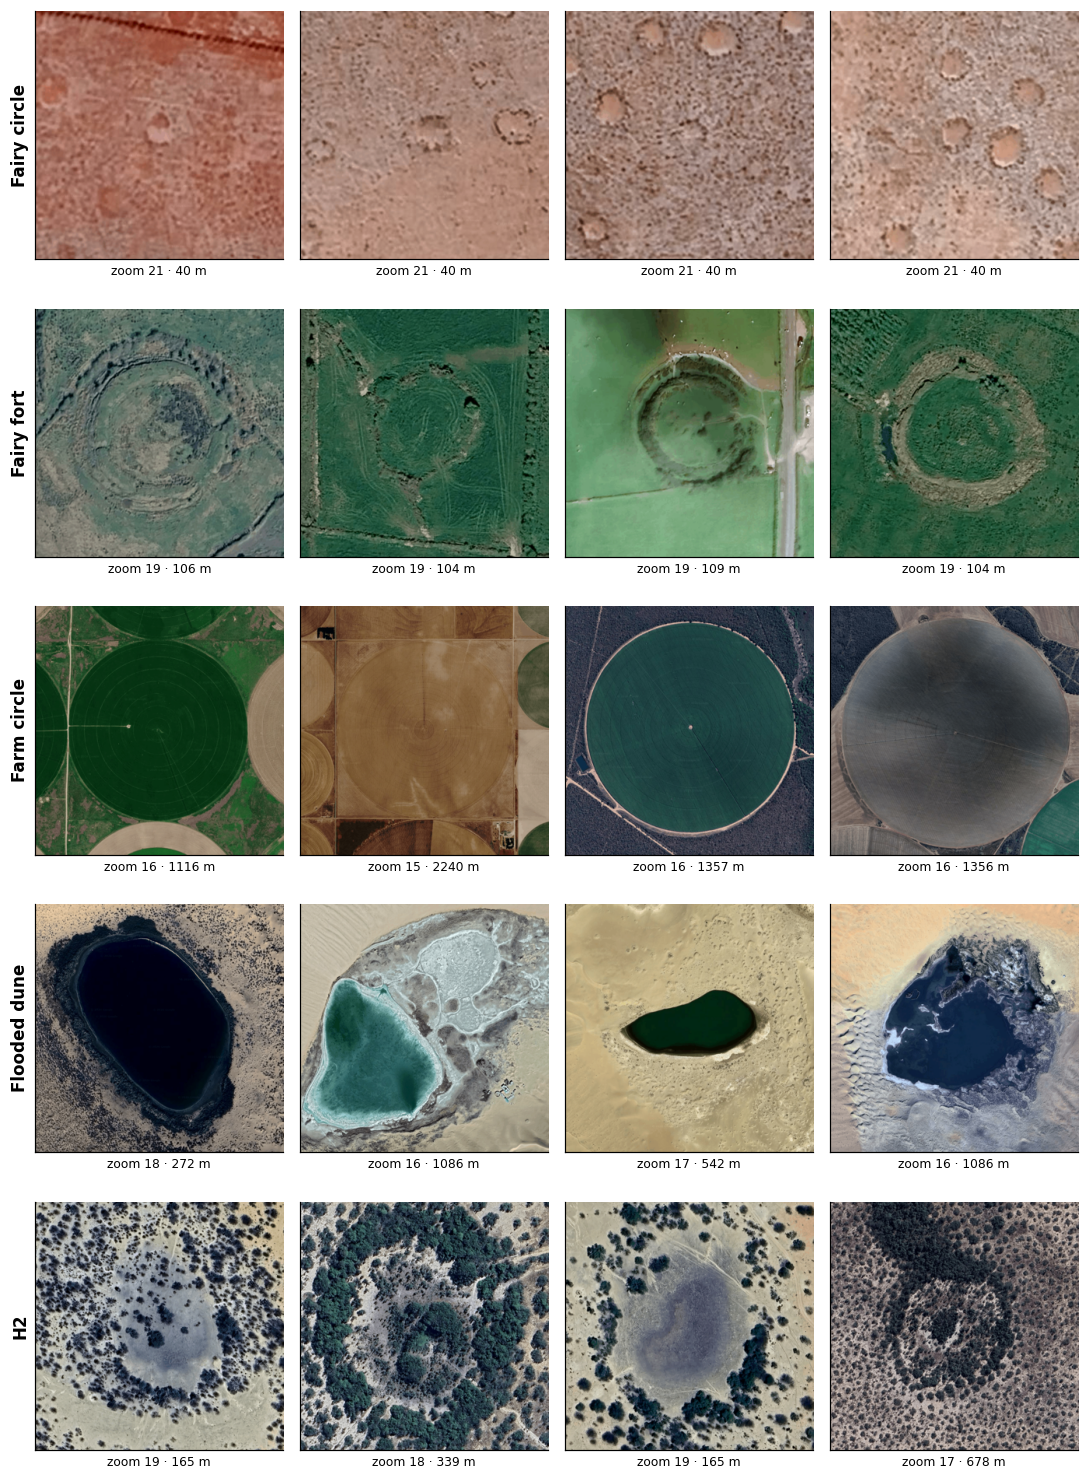

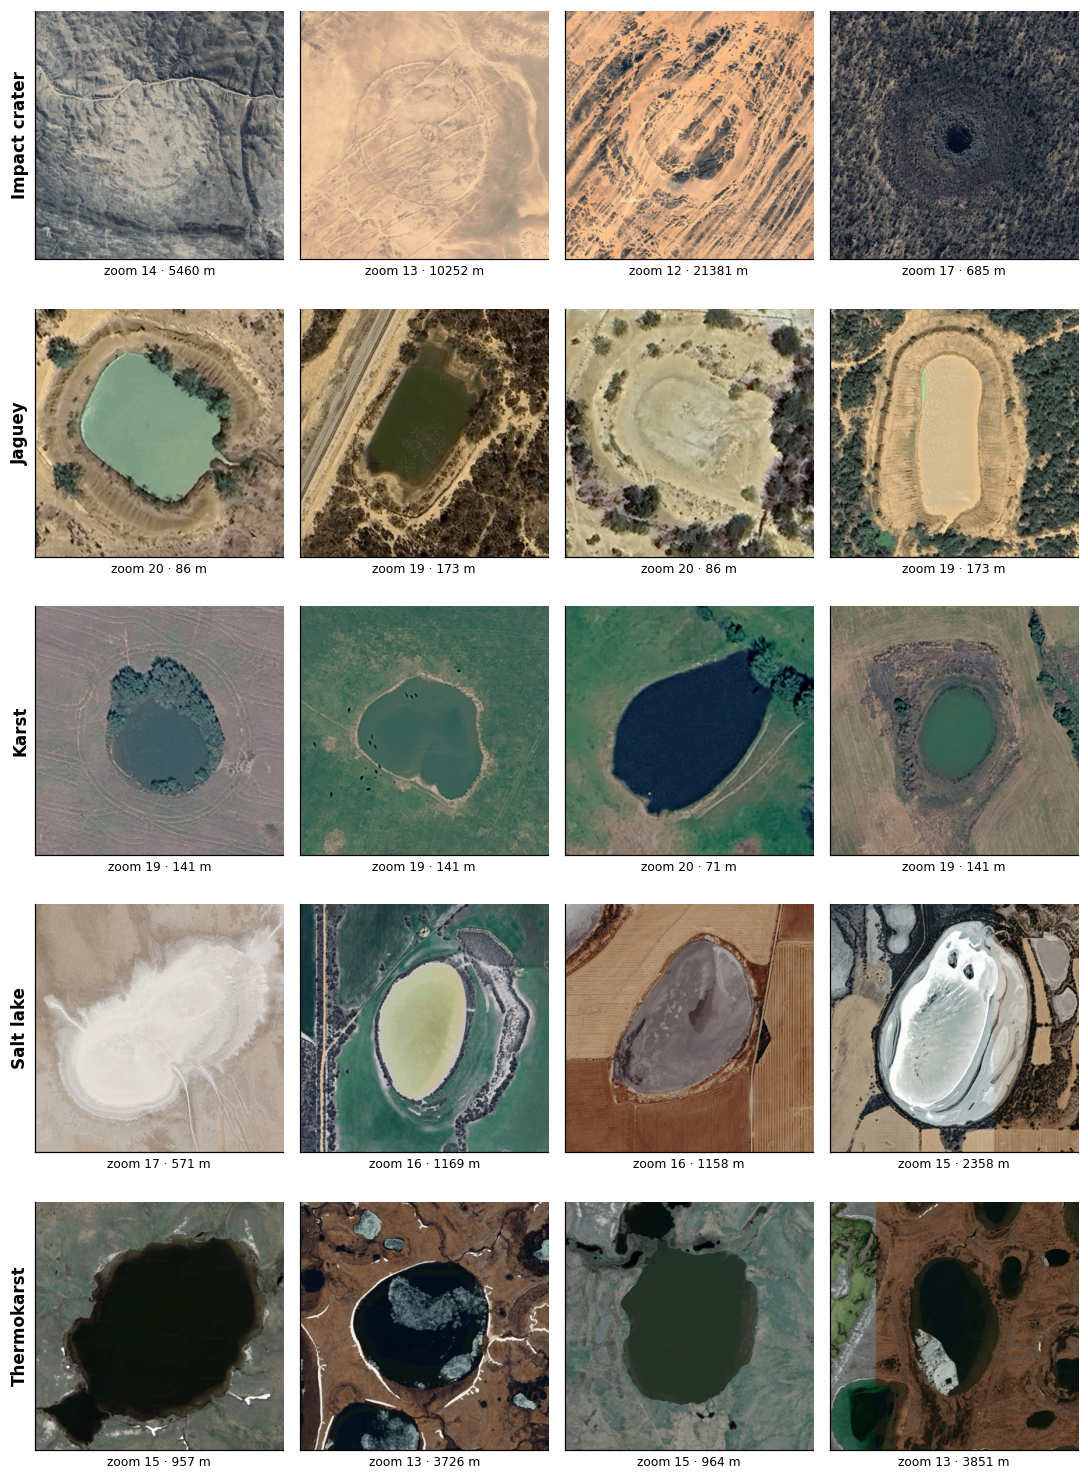

In [ ]:
rng = np.random.default_rng(SEMILLA)
ejemplos = {c: un_ejemplo_por_sitio(cv[cv["clase"] == c], 4, rng) for c in clases}
for grupo in (clases[:5], clases[5:]):
    fig, ejes = plt.subplots(len(grupo), 4, figsize=(10, 2.75 * len(grupo)))
    for fila, clase in enumerate(grupo):
        for col, (_, im) in enumerate(ejemplos[clase].iterrows()):
            ax = ejes[fila, col]
            ax.imshow(miniatura(im["ruta"])); ax.set_xticks([]); ax.set_yticks([])
            ax.set_xlabel(f"zoom {im['zoom']} · {im['huella_lado_m']:.0f} m", fontsize=8)
        ejes[fila, 0].set_ylabel(clase, fontsize=11, fontweight="bold")
    fig.tight_layout()
    plt.show()

## 2.3 ¿El zoom delata la clase?

A mayor zoom, más detalle y menos terreno en el cuadro. Si una clase se capturó casi siempre con un zoom que las demás no usan, un modelo podría reconocerla por la resolución y no por la forma. El mapa de calor cuenta cuántas imágenes de cada clase (filas) hay en cada nivel de zoom (columnas).

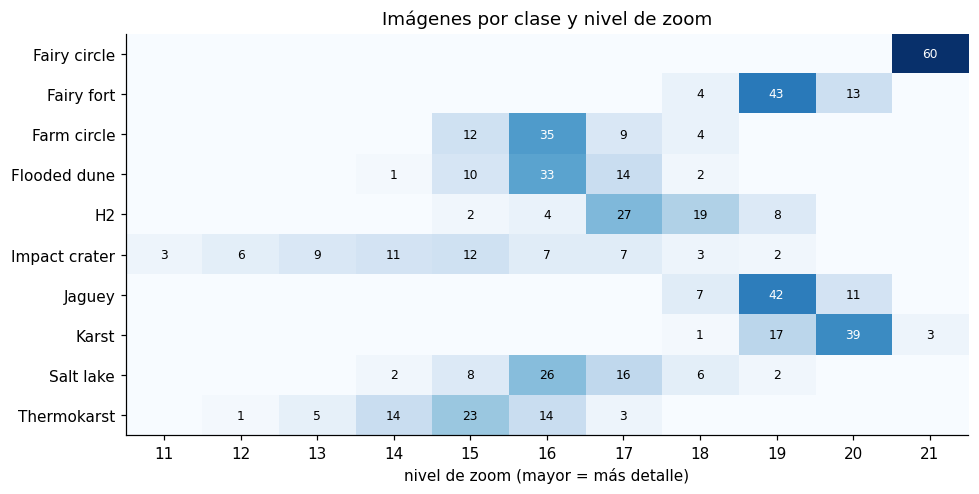

In [ ]:
tabla_zoom = pd.crosstab(part["clase"], part["zoom"])
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.imshow(tabla_zoom.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(tabla_zoom.shape[1]), tabla_zoom.columns); ax.set_yticks(range(len(tabla_zoom)), tabla_zoom.index)
for (i, j), v in np.ndenumerate(tabla_zoom.values):
    if v:
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > 0.5 * tabla_zoom.values.max() else "black")
ax.set_xlabel("nivel de zoom (mayor = más detalle)"); ax.set_title("Imágenes por clase y nivel de zoom")
fig.tight_layout()
plt.show()

Los zooms van de 11 a 21. Fairy circle usa uno solo (21) en sus 60 imágenes. Fairy fort (72 % en zoom 19), Jagüey (70 % en 19), Karst (65 % en 20), Farm circle (58 % en 16) y Flooded dune (55 % en 16) tienen más de la mitad de sus imágenes en un mismo zoom. Impact crater es la más dispersa, con nueve niveles entre 11 y 19; H2, Salt lake y Thermokarst no tienen un zoom dominante.

### ¿Cuánto se acierta solo con el zoom?

Para medirlo se usa un **bosque aleatorio**, un modelo clásico que aprende reglas simples del tipo «si el zoom es mayor que 19, probablemente es tal clase» y hace votar a muchas de ellas. No ve ninguna imagen, solo el número del zoom. Se evalúa con los pliegues del notebook 1: se entrena con cuatro y se predice el quinto, cinco veces, así que cada predicción es sobre imágenes que no usó para aprender.

Se reportan dos medidas. El **recall** de una clase es la fracción de sus imágenes que se reconoce (0,76 significa 76 de cada 100). La **exactitud balanceada** es el promedio del recall de las clases, de modo que una clase fácil no esconda los fallos de otra. Al azar, con 10 clases, se acierta el 10 %. Lo que se logra así, sin mirar la forma, es un **piso**: lo mínimo que un modelo de imágenes debe superar con claridad para demostrar que aprende algo más que resolución o color.

In [ ]:
solo_zoom = piso(["zoom"])
print(f"Exactitud balanceada con solo el zoom: {solo_zoom['exactitud_balanceada']:.1%} (azar: {1 / len(clases):.0%})")
display(solo_zoom["recall"].round(2).rename("recall con solo el zoom").to_frame().T)

Exactitud balanceada con solo el zoom: 46.4% (azar: 10%)


,Fairy circle,Fairy fort,Farm circle,Flooded dune,H2,Impact crater,Jaguey,Karst,Salt lake,Thermokarst
recall con solo el zoom,1.0,0.32,0.62,0.0,0.76,0.3,0.28,0.7,0.0,0.66


Con solo el zoom se acierta el 46 %, casi cinco veces el azar. Fairy circle se reconoce al 100 %, H2 al 76 % y Karst al 70 %.

## 2.4 ¿El color delata la clase?

La misma pregunta con el aspecto general de la imagen. Para cada imagen se calculan cinco números: el **color medio** en rojo, verde y azul (de 0 a 255), el **brillo** (qué tan clara es en promedio) y el **contraste** (cuánto varía el brillo dentro de la imagen). Es normal que cada terreno tenga colores propios; lo que importa es cuánto de un buen resultado podría venir solo de ahí. Se repite la prueba anterior con el color y el contraste, y luego con estos junto con el zoom.

En la primera figura, cada barra de la izquierda es el color medio de una clase; a la derecha, un diagrama de caja del brillo (la caja abarca el 50 % central de las imágenes, la línea es la mediana y los puntos son imágenes atípicas). En la segunda, cada clase tiene tres barras con su recall según lo que ve el bosque aleatorio; la línea punteada es el azar.

,rojo,verde,azul,brillo,contraste
clase,,,,,
Fairy circle,165.6,131.2,118.0,138.3,15.4
Fairy fort,66.6,97.9,83.5,82.7,15.5
Farm circle,89.5,82.5,67.2,79.7,32.1
Flooded dune,141.6,131.7,114.3,129.2,48.5
H2,100.1,101.8,100.7,100.9,35.0
Impact crater,122.2,111.2,99.8,111.1,24.0
Jaguey,128.2,116.4,91.4,112.0,38.7
Karst,102.2,109.4,91.3,100.9,21.3
Salt lake,121.7,113.8,102.7,112.7,40.3


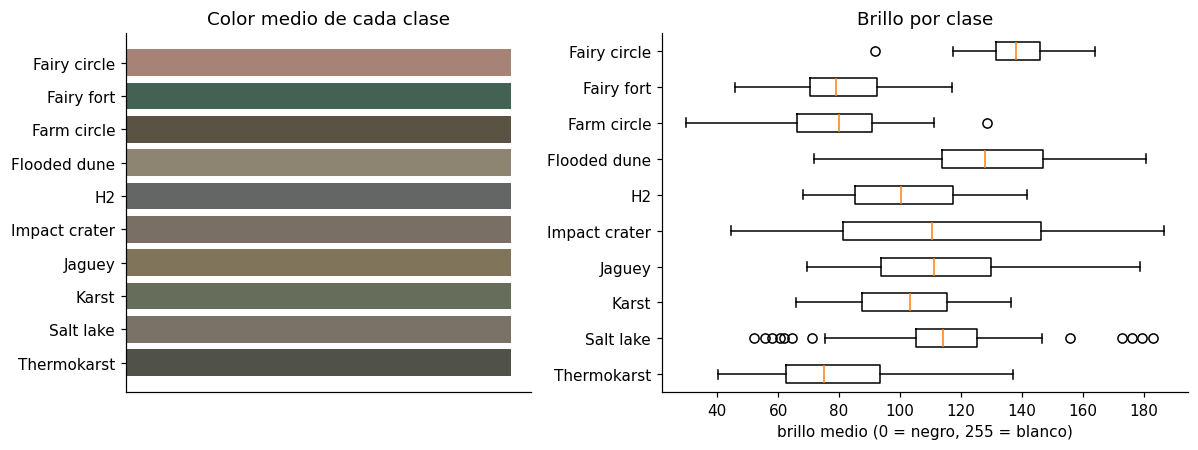

In [ ]:
color = pd.DataFrame([color_y_contraste(r) for r in part["ruta"]], index=part.index)
part = part.join(color)
cv = part[part["split"] == "cv"]

resumen_color = part.groupby("clase")[list(color.columns)].mean().round(1)
display(resumen_color)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
ejes[0].barh(resumen_color.index, np.ones(len(resumen_color)), color=resumen_color[["rojo", "verde", "azul"]].to_numpy() / 255)
ejes[0].set_xticks([]); ejes[0].invert_yaxis(); ejes[0].set_title("Color medio de cada clase")
ejes[1].boxplot([part.loc[part["clase"] == c, "brillo"] for c in clases], tick_labels=clases, vert=False)
ejes[1].invert_yaxis(); ejes[1].set_xlabel("brillo medio (0 = negro, 255 = blanco)"); ejes[1].set_title("Brillo por clase")
fig.tight_layout()
plt.show()

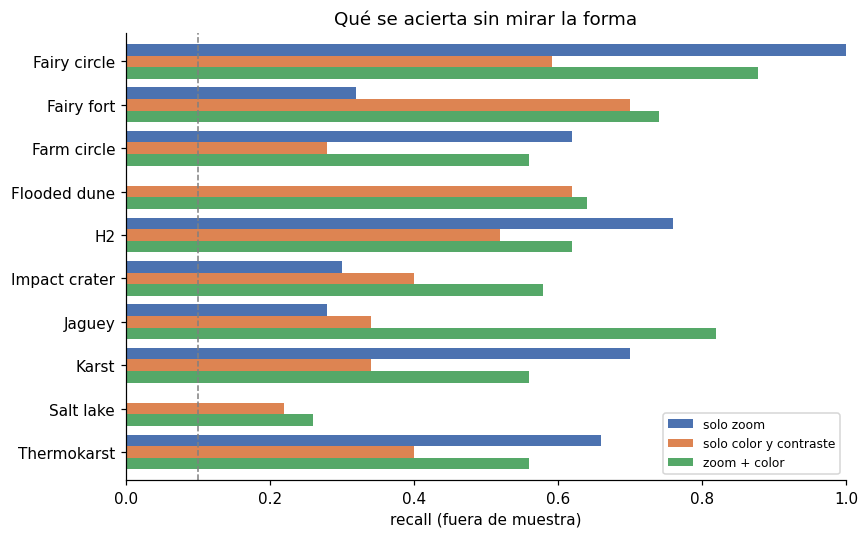

,solo zoom,solo color y contraste,zoom + color
exactitud_balanceada,0.464,0.4412,0.6218


In [ ]:
solo_color = piso(["rojo", "verde", "azul", "brillo", "contraste"])
zoom_y_color = piso(["zoom", "rojo", "verde", "azul", "brillo", "contraste"])
pisos = {"solo zoom": solo_zoom, "solo color y contraste": solo_color, "zoom + color": zoom_y_color}

fig, ax = plt.subplots(figsize=(8, 5))
pd.DataFrame({nombre: p["recall"] for nombre, p in pisos.items()}).plot.barh(ax=ax, width=0.8, color=["#4C72B0", "#DD8452", "#55A868"])
ax.axvline(1 / len(clases), color="gray", ls="--", lw=1)
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_ylabel("")
ax.set_xlabel("recall (fuera de muestra)"); ax.set_title("Qué se acierta sin mirar la forma")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

tabla_pisos = pd.Series({nombre: p["exactitud_balanceada"] for nombre, p in pisos.items()}, name="exactitud_balanceada").round(4)
display(tabla_pisos.to_frame().T)
tabla_pisos.rename_axis("linea_base").to_csv(OUT_DIR / "lineas_base.csv", sep=";", encoding="utf-8-sig")   # los usa el notebook 3

Con color y contraste se acierta el 44 %, y con el zoom además, el 62 %, frente al 10 % del azar. Con zoom y color se reconocen al 70 % o más Fairy circle, Jagüey y Fairy fort; H2 y Karst quedan por debajo de lo que lograban con solo el zoom, y Salt lake es la más baja (26 %). El color por sí solo delata sobre todo a Fairy fort (70 %), Flooded dune (62 %) y Fairy circle (59 %).

Estos son los pisos que el notebook 3 compara con los modelos de imágenes.

## 2.5 Dónde están las imágenes

La ubicación importa por dos razones: si una clase viene de una sola región, el modelo podría aprender el paisaje de esa región en lugar de la forma; y muestra cuánta diversidad geográfica hay detrás de cada clase. Además del mapa se calcula, por clase, la **dispersión mediana**: la distancia mediana, en kilómetros, de sus imágenes al punto central de la clase. Vale 0 si todas están en el mismo lugar y miles de kilómetros si se reparten por el mundo.

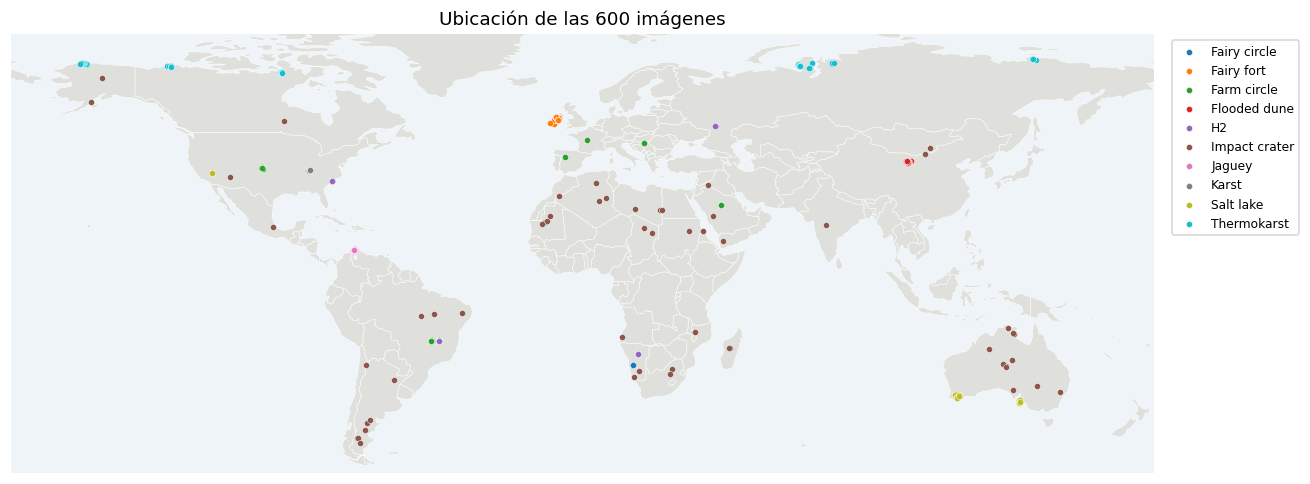

,sitios reales,dispersión mediana (km)
Fairy circle,3,0
Fairy fort,33,12
Farm circle,54,5101
Flooded dune,59,16
H2,40,6585
Impact crater,59,7581
Jaguey,46,20
Karst,14,19
Salt lake,52,142
Thermokarst,56,3017


In [ ]:
fig, ax = plt.subplots(figsize=(12, 5.6))
fondo_mundo(ax)
for i, clase in enumerate(clases):
    sub = part[part["clase"] == clase]
    ax.scatter(sub["lon"], sub["lat"], s=16, color=plt.get_cmap("tab10")(i), edgecolor="white", linewidth=0.3, label=clase)
ax.set_title(f"Ubicación de las {len(part)} imágenes")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

dispersion = {}
for clase, sub in part.groupby("clase"):
    centro = sub[["lat", "lon"]].median()
    dispersion[clase] = np.median(haversine_km(sub["lat"].values, sub["lon"].values, np.array([centro["lat"]]), np.array([centro["lon"]])))
display(pd.DataFrame({"sitios reales": part.groupby("clase")["grupo_particion"].nunique(),
                      "dispersión mediana (km)": pd.Series(dispersion).round(0).astype(int)}))

Cinco clases están concentradas en una zona pequeña, con dispersión mediana menor de 100 km: Fairy circle (0 km, todas en el mismo lugar), Fairy fort (12 km), Flooded dune (16 km), Karst (19 km) y Jagüey (20 km). Según sus coordenadas están en Namibia, Irlanda, el norte de China, Kentucky (Estados Unidos) y la Alta Guajira (Colombia). Salt lake es algo más abierta (142 km), y Thermokarst, Farm circle, H2 e Impact crater se reparten por el mundo, con dispersiones de 3.000 a 7.600 km. En las clases concentradas, un modelo podría asociar la clase con el paisaje de su región y no con la forma.

### Las regiones de H2

La dispersión de H2 no significa que sus imágenes estén repartidas de forma pareja: vienen de unas pocas regiones. Se agrupan las H2 de validación cruzada en regiones, juntando las imágenes unidas por saltos de menos de 1.000 km, y cada región se nombra por su latitud y longitud aproximadas.

In [ ]:
h2 = cv[cv["clase"] == "H2"].copy()
h2["región"] = regiones(h2["lat"], h2["lon"])
display(h2.groupby("región", sort=False).agg(imágenes=("id", "size"), sitios=("grupo_particion", "nunique"),
                                              zooms=("zoom", lambda z: ", ".join(map(str, sorted(z.unique()))))))

,imágenes,sitios,zooms
región,,,
51°N 42°E,10,3,"15, 16, 17, 18"
21°S 18°E,15,8,"18, 19"
16°S 45°O,22,19,"17, 18"
34°N 79°O,3,2,"15, 17, 18"


Las 50 H2 de validación cruzada vienen de cuatro regiones: 22 del centro de Brasil (16°S 45°O, 19 sitios), 15 de Namibia y el norte de Sudáfrica (21°S 18°E, 8 sitios), 10 del sur de Rusia (51°N 42°E, solo 3 sitios) y 3 de las Carolinas, en Estados Unidos (34°N 79°O, 2 sitios). Cada región tiene su propio paisaje y su propio rango de zoom, lo que explica en parte que el zoom solo reconozca el 76 % de las H2. Para el modelo, H2 no es una clase repartida por el mundo, sino cuatro paisajes distintos; el notebook 3 muestra cómo se refleja eso en su desempeño.

### El caso de los Jagüeyes

Los Jagüeyes son las únicas imágenes de la Alta Guajira, la región donde están las 120 estructuras que se quieren priorizar. El reto central del proyecto es distinguir H2 de Jagüey, y si solo los Jagüeyes tienen paisaje guajiro, el modelo podría separarlos por el paisaje. La tabla cuenta cuántas imágenes de cada clase están a menos de 300 km del centro de los Jagüeyes.

In [ ]:
centro_jaguey = part.loc[part["clase"] == "Jaguey", ["lat", "lon"]].median()
km_a_jaguey = haversine_km(part["lat"].values, part["lon"].values, np.array([centro_jaguey["lat"]]), np.array([centro_jaguey["lon"]]))[:, 0]
display(part[km_a_jaguey < 300].groupby("clase").size().reindex(clases, fill_value=0).rename("a menos de 300 km de los Jagüeyes").to_frame().T)

clase,Fairy circle,Fairy fort,Farm circle,Flooded dune,H2,Impact crater,Jaguey,Karst,Salt lake,Thermokarst
a menos de 300 km de los Jagüeyes,0,0,0,0,0,0,60,0,0,0


Las 60 imágenes de Jagüey están en ese radio y ninguna de las otras nueve clases tiene una sola, tampoco H2. En este dataset todo lo de la guajira es Jagüey, así que el modelo podría separarlos de H2 por el paisaje y no solo por la forma. El notebook 4 lo mide directamente.

## Resumen

- 600 imágenes de 10 clases, con 11 niveles de zoom y huellas de 35 m a 42 km de lado.
- Solo con el zoom se acierta el 46 % (azar: 10 %); Fairy circle, H2 y Karst se reconocen por él al 70 % o más.
- Con color y contraste se acierta el 44 %, y con zoom y color, el 62 %. Esos son los pisos que un modelo de imágenes debe superar.
- Fairy circle, Fairy fort, Flooded dune, Karst y Jagüey están concentradas en zonas pequeñas; los Jagüeyes son las únicas imágenes de La Guajira.
- H2 viene de cuatro regiones (Brasil, Namibia, Rusia y las Carolinas), cada una con su paisaje y su zoom.

El siguiente paso es `03_modelamiento.ipynb`.